In [5]:
from ObjaverseDataset import ObjaverseDataset
from torch.utils.data import DataLoader
from pathlib import Path
from utils import *

In [6]:
objaverse_dataset = ObjaverseDataset(category="cat", limit=3)
objaverse_dataloader = DataLoader(objaverse_dataset, batch_size=1, shuffle=False, collate_fn=objaverse_dataset.collate_fn)

dict_keys(['Band_Aid', 'Bible', 'CD_player', 'Christmas_tree', 'Dixie_cup', 'Ferris_wheel', 'Lego', 'Rollerblade', 'Sharpie', 'Tabasco_sauce', 'aerosol_can', 'air_conditioner', 'airplane', 'alarm_clock', 'alcohol', 'alligator', 'almond', 'ambulance', 'amplifier', 'anklet', 'antenna', 'apple', 'apricot', 'apron', 'aquarium', 'arctic_(type_of_shoe)', 'armband', 'armchair', 'armoire', 'armor', 'army_tank', 'artichoke', 'ashtray', 'asparagus', 'atomizer', 'automatic_washer', 'avocado', 'award', 'awning', 'ax', 'baboon', 'baby_buggy', 'backpack', 'bagel', 'baguet', 'bait', 'ball', 'ballet_skirt', 'balloon', 'bamboo', 'banana', 'bandage', 'bandanna', 'banjo', 'banner', 'barbell', 'barge', 'barrel', 'barrow', 'baseball', 'baseball_bat', 'baseball_cap', 'baseball_glove', 'basket', 'basketball', 'basketball_backboard', 'bass_horn', 'bat_(animal)', 'bath_mat', 'bath_towel', 'bathrobe', 'bathtub', 'battery', 'beachball', 'bead', 'beanbag', 'beanie', 'bear', 'bed', 'bedpan', 'bedspread', 'beef_(fo

In [7]:
import utils
import importlib


importlib.reload(utils)

<module 'utils' from '/Users/marinazaspa/PycharmProjects/vlm-based-3d-shape-editing/utils.py'>

=== Processing UID: ['1f32bc0b4dd740f49faefc1cbe0e5e45'] ===
FEngine (64 bits) created at 0x318a13e00 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M1'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1


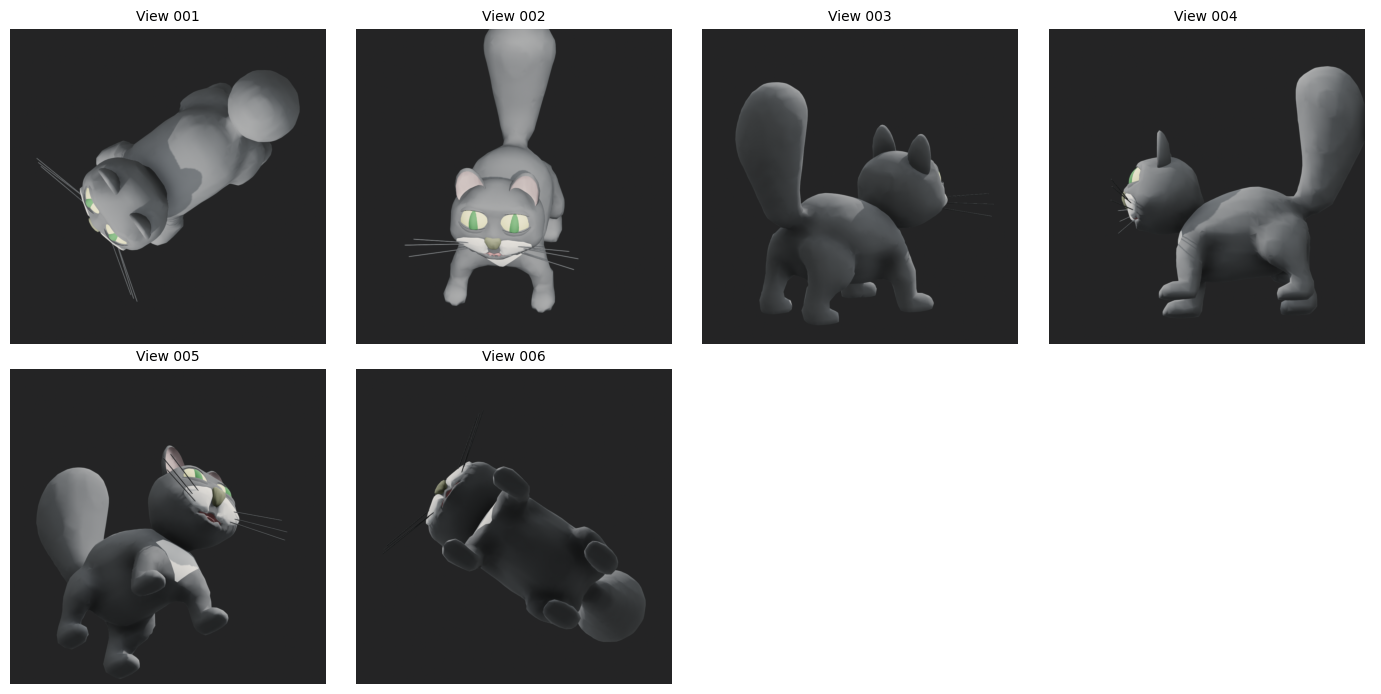

./weights are already installed
Image size (H, W, C): (1008, 1008, 3)


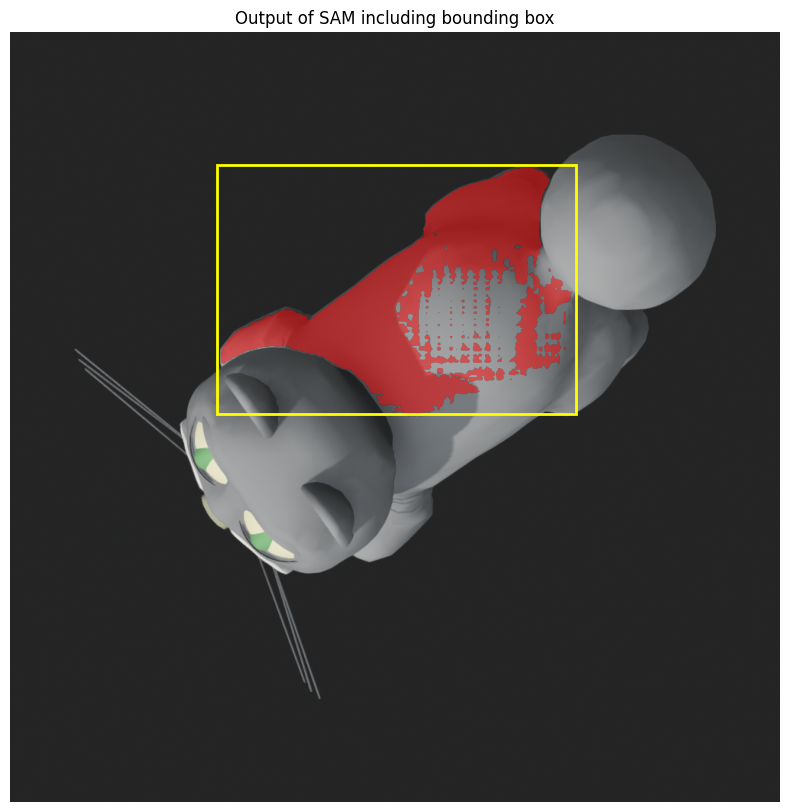

Added (mask, eye_pos) pair to valid_masks_set
./weights are already installed
Image size (H, W, C): (1008, 1008, 3)


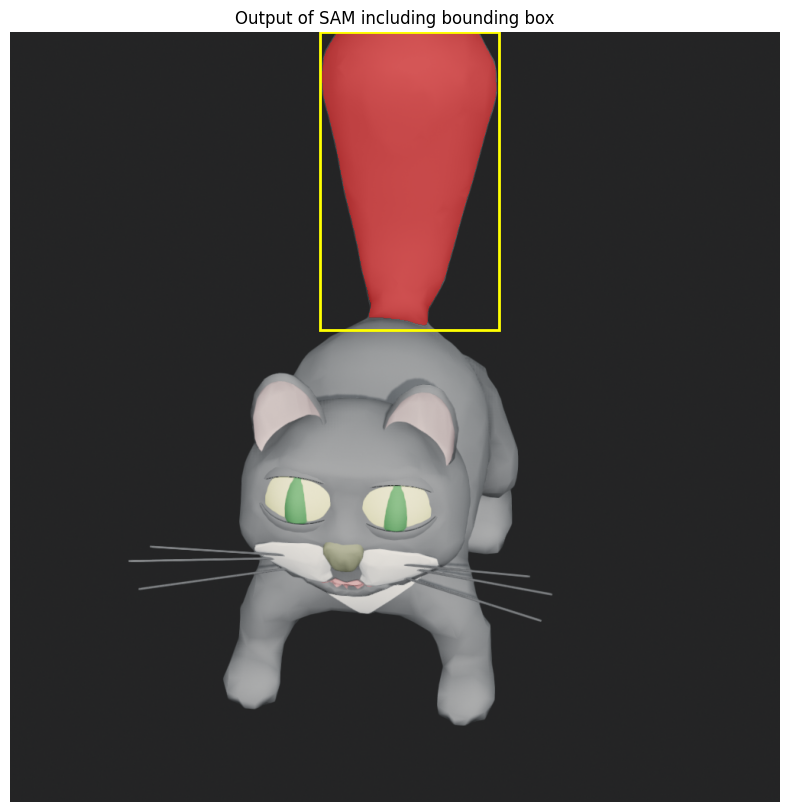

Added (mask, eye_pos) pair to valid_masks_set
./weights are already installed
Image size (H, W, C): (1008, 1008, 3)


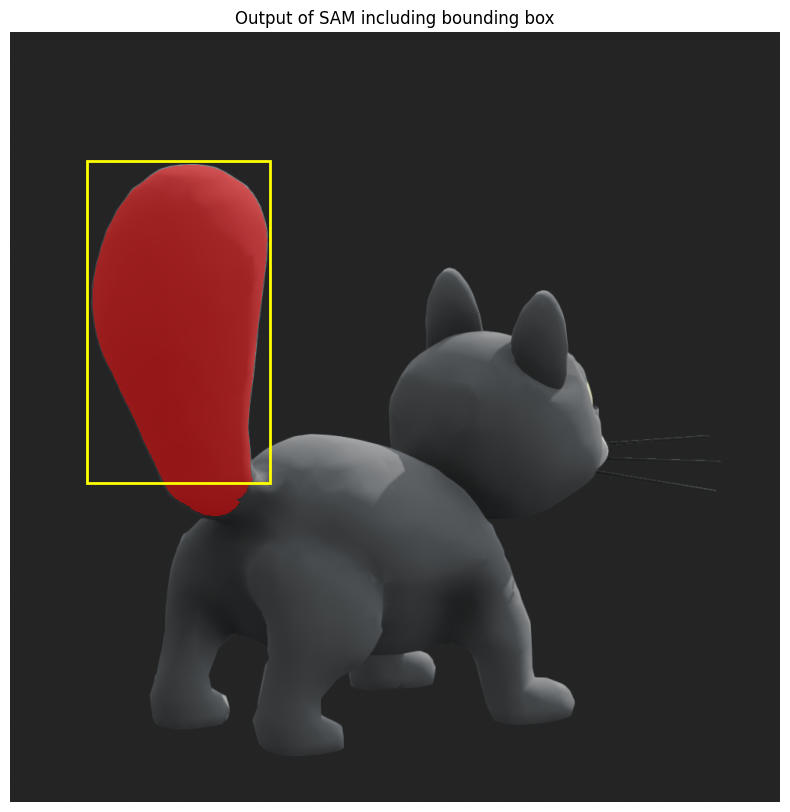

Added (mask, eye_pos) pair to valid_masks_set
./weights are already installed
Image size (H, W, C): (1008, 1008, 3)


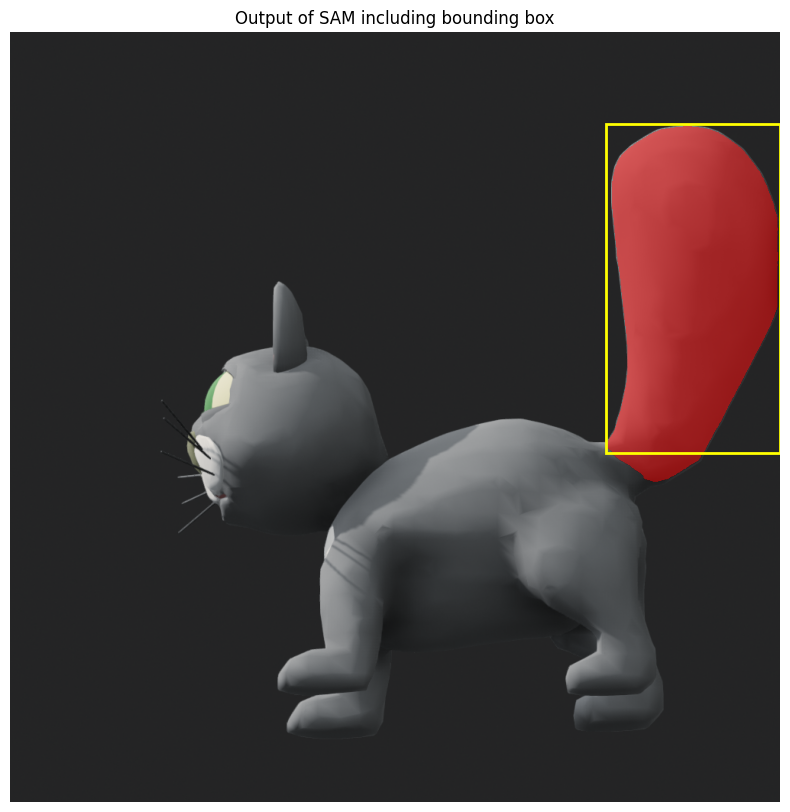

Added (mask, eye_pos) pair to valid_masks_set
./weights are already installed
Image size (H, W, C): (1008, 1008, 3)


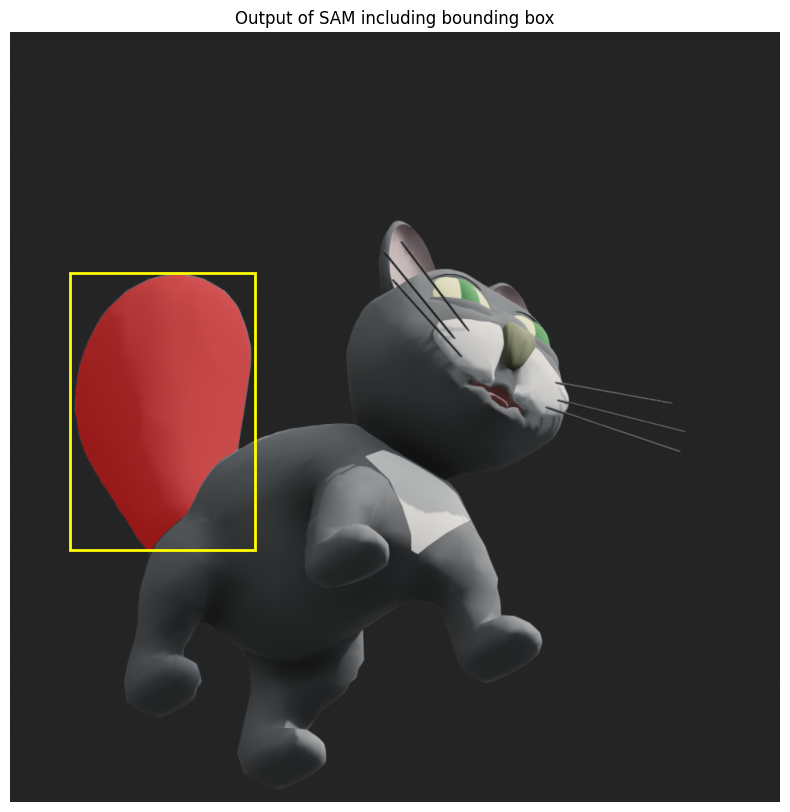

Added (mask, eye_pos) pair to valid_masks_set
./weights are already installed
Image size (H, W, C): (1008, 1008, 3)


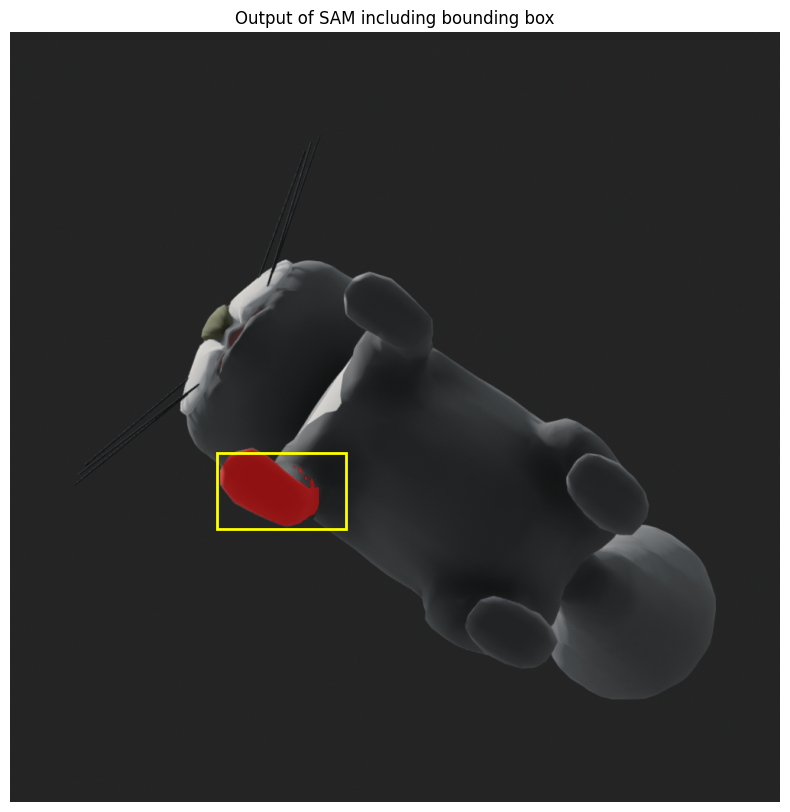

Added (mask, eye_pos) pair to valid_masks_set


UID: ['1f32bc0b4dd740f49faefc1cbe0e5e45'] | Вершин попало в маску: 321


=== Processing UID: ['138377b0ab2847f081e3a6a5210516e6'] ===


In [ ]:
import json
from IPython.display import display
from pathlib import Path

feature_to_detect = "tail"

# Обработка всех 3D объектов в DataLoader
for batch in objaverse_dataloader:
    uid = batch["uid"]
    print(f"=== Processing UID: {uid} ===")

    # Безопасное получение меша
    mesh = batch["mesh"][0] if isinstance(batch["mesh"], list) else batch["mesh"]
    output_dir = f"rendered_views/{uid}"

    # 1. Рендерим ракурсы и сразу получаем список кортежей [(eye_pos, file_path), ...]
    rendered_info = render_n_views(mesh, n_views=6, output_dir=output_dir)
    show_rendered_grid(output_dir)

    valid_masks_set = []  # Хранит пары (mask, eye_pos)

    # 2. Проходим напрямую по переданным ракурсам без обхода директории
    for eye_pos, view_path in rendered_info:
        view_path_str = str(view_path)

        # Детекция объекта
        json_output = generate_bounding_box_for_image("192.168.178.23", view_path_str, feature_to_detect, temperature=0.1)
        data = json.loads(json_output)

        if not data.get('is_found', False):
            print(f"Feature '{feature_to_detect}' not found on {view_path_str}")
            visualize_segmentation(image_path=view_path_str, mask=None, x1=0, y1=0, x2=1000, y2=1000)
            continue

        # Извлечение 2D bounding box
       # Извлечение 2D bounding box (теперь строго xmin, ymin, xmax, ymax)
        xmin, ymin, xmax, ymax = data['bbox_2d']

        # Передаем в сегментацию в правильном порядке
        mask = segment_image(view_path_str, xmin, ymin, xmax, ymax)
        visualize_segmentation(image_path=view_path_str, mask=mask, x1=xmin, y1=ymin, x2=xmax, y2=ymax)

        # 3. Сохраняем пару (маска, позиция камеры)
        valid_masks_set.append((mask, eye_pos))
        print("Added (mask, eye_pos) pair to valid_masks_set")

    # 4. Проекция на 3D модель и отображение результата


    if valid_masks_set:
        dense_mesh = mesh.subdivide()
        colored_mesh, mask_submesh = project_masks_to_3d(mesh, valid_masks_set)
        display(mask_submesh.show())
        # 1. Сбрасываем текстуру и переводим в ColorVisuals ДО вызова проекции
        mesh.visual = trimesh.visual.ColorVisuals(mesh=mesh)

        # 2. Вызываем проекцию
        colored_mesh, mask_submesh = project_masks_to_3d(mesh, valid_masks_set)

        # Проверка: сколько вершин действительно окрасилось в зеленый цвет
        green_vertices = (colored_mesh.visual.vertex_colors[:, 1] == 255).sum()
        print(f"UID: {uid} | Вершин попало в маску: {green_vertices}")

        # 3. Отображение

        display(colored_mesh.show())
    else:
        print(f"No valid masks generated for UID: {uid}")